#**TP 2 - ESTATÍSTICA APLICADA E ANÁLISE EXPLORATÓRIA DE DADOS**

#CÓDIGO PARA GERAÇÃO DOS DATASETS

In [46]:
import numpy as np
import pandas as pd
import json
from datetime import datetime, timedelta

In [47]:
rng = np.random.default_rng(42)
n = 4000
start_date = datetime(2026, 1, 5)

ticket_ids = [f"TCK-{i:05d}" for i in range(1, n + 1)]
cliente_ids = [f"CLI-{i:03d}" for i in rng.integers(1, 181, n)]
dias_offset = np.sort(rng.integers(0, 180, n))
datas = [(start_date + timedelta(days=int(d))).strftime("%Y-%m-%d") for d in dias_offset]
canais = rng.choice(["email", "chat", "telefone"], size=n, p=[0.45, 0.35, 0.20])
categorias = rng.choice(["bug", "duvida_de_uso", "cobranca", "elogio"], size=n, p=[0.35, 0.30, 0.25, 0.10])
prioridades = rng.choice(["baixa", "media", "alta", "critica"], size=n, p=[0.30, 0.35, 0.25, 0.10])
tempo_resposta = np.clip(rng.gamma(shape=2.0, scale=2.2, size=n), 0.2, 48)
tempo_resposta[canais == "chat"] *= 0.6
tempo_resolucao = np.clip(1.8 * tempo_resposta + 3 + rng.normal(0, 1.5, n), 0.5, 120)
satisfacao = 5 - (tempo_resposta / 6) + rng.normal(0, 0.6, n)
satisfacao[canais == "chat"] -= 0.6
satisfacao = np.clip(np.round(satisfacao), 1, 5)

df = pd.DataFrame({
    "ticket_id": ticket_ids,
    "cliente_id": cliente_ids,
    "data_abertura": datas,
    "canal": canais,
    "categoria": categorias,
    "prioridade": prioridades,
    "tempo_resposta_horas": tempo_resposta,
    "tempo_resolucao_horas": tempo_resolucao,
    "satisfacao_cliente": satisfacao,
})

# valores ausentes (como em uma exportação real)
df.loc[rng.choice(n, size=int(n * 0.08), replace=False), "tempo_resposta_horas"] = np.nan
df.loc[rng.choice(n, size=int(n * 0.10), replace=False), "satisfacao_cliente"] = np.nan

# tempo_resposta_horas exportado como texto, com vírgula decimal
def fmt_virgula(v):
    return "" if pd.isna(v) else f"{v:.2f}".replace(".", ",")

df["tempo_resposta_horas"] = df["tempo_resposta_horas"].apply(fmt_virgula)

# duplicatas de reenvio, anexadas ao final (não afetam a ordem cronológica das primeiras n linhas)
duplicatas = df.sample(frac=0.02, random_state=42)
df_final = pd.concat([df, duplicatas], ignore_index=True)
df_final.to_csv("tickets_suporte.csv", index=False)

In [ ]:
# planos_clientes.xlsx
clientes_unicos = sorted(set(cliente_ids))
planos = pd.DataFrame({
    "cliente_id": clientes_unicos,
    "valor_plano": rng.choice([99.0, 199.0, 349.0, 599.0], size=len(clientes_unicos), p=[0.4, 0.3, 0.2, 0.1]),
    "segmento": rng.choice(["starter", "growth", "enterprise"], size=len(clientes_unicos), p=[0.5, 0.35, 0.15]),
})
planos.to_excel("planos_clientes.xlsx", index=False)

In [ ]:
# chatbot_triagem.json (apenas tickets abertos pelo canal chat)
chat_ids = df.loc[df["canal"] == "chat", "ticket_id"].tolist()
triagem = [
    {
        "ticket_id": tid,
        "intencao_triagem": str(rng.choice(["duvida", "reclamacao", "solicitacao", "elogio"])),
        "confianca_bot": round(float(rng.uniform(0.55, 0.98)), 2),
    }
    for tid in chat_ids
]

with open("chatbot_triagem.json", "w", encoding="utf-8") as f:
    json.dump(triagem, f, ensure_ascii=False, indent=2)

#TP 2

## Carga dos arquivos e limpeza e preparação dos dados

In [48]:
df_tickets = pd.read_csv("tickets_suporte.csv")
df_planos = pd.read_excel("planos_clientes.xlsx")
df_triagem = pd.read_json("chatbot_triagem.json")

df_tickets["data_abertura"] = df_tickets["data_abertura"].astype("datetime64[ns]")
df_tickets["tempo_resposta_horas"] = (
    df_tickets["tempo_resposta_horas"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

mediana_por_categoria = df_tickets.groupby("categoria")["tempo_resposta_horas"].transform("median")
df_tickets["tempo_resposta_horas"] = df_tickets["tempo_resposta_horas"].fillna(mediana_por_categoria)
df_tickets = df_tickets.dropna(subset=["ticket_id"])
df_tickets = df_tickets.drop_duplicates(subset=["ticket_id"], keep="first")

df_consolidado = pd.merge(df_tickets, df_planos, on="cliente_id", how="left")
df_consolidado = pd.merge(df_consolidado, df_triagem, on="ticket_id", how="left")

print("shape final:")
print(df_consolidado.shape)



shape final:
(4000, 13)


## Imports

In [49]:
import numpy as np
import pandas as pd
import json
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

#TP2 - Respostas

##**EXERCÍCIO 1**

### 1.1 Calcule a probabilidade de um ticket ser de prioridade "alta" (P(alta)) usando a frequência relativa observada na base de tickets.

In [52]:
p_alta = (df_consolidado["prioridade"] == "alta").mean()
print("P(alta):", round(p_alta, 4))

P(alta): 0.254


### 1.2 Calcule a probabilidade condicional de um cliente abrir um segundo ticket na mesma semana, dado que o primeiro foi de prioridade "alta", usando a regra da multiplicação.

In [53]:
df_consolidado["ano_semana"] = df_consolidado["data_abertura"].dt.strftime("%G-%V")

grupos_semana = (
    df_consolidado
    .sort_values(["cliente_id", "ano_semana", "data_abertura"])
    .groupby(["cliente_id", "ano_semana"])
)

primeiro_ticket_semana = grupos_semana.first()
primeiro_ticket_semana["tem_segundo_ticket"] = (grupos_semana.size() > 1).values
primeiro_ticket_semana["primeiro_eh_alta"] = primeiro_ticket_semana["prioridade"] == "alta"

p_a = primeiro_ticket_semana["primeiro_eh_alta"].mean()
p_a_e_b = (primeiro_ticket_semana["primeiro_eh_alta"] & primeiro_ticket_semana["tem_segundo_ticket"]).mean()
p_b_dado_a = p_a_e_b / p_a

print("Combinações cliente-semana:", len(primeiro_ticket_semana))
print("P(primeiro ticket da semana = alta):", round(p_a, 4))
print("P(primeiro = alta E existe segundo ticket na semana):", round(p_a_e_b, 4))
print("P(segundo ticket | primeiro = alta):", round(p_b_dado_a, 4))

Combinações cliente-semana: 2683
P(primeiro ticket da semana = alta): 0.2538
P(primeiro = alta E existe segundo ticket na semana): 0.0906
P(segundo ticket | primeiro = alta): 0.3568


Como a base não tem uma coluna de semana pronta, defini semana como o par (cliente_id, semana ISO de data_abertura), o que gera 2683 combinações cliente-semana distintas. Para cada combinação, marquei o primeiro ticket cronológico e se houve um segundo ticket naquela mesma semana. Pela regra da multiplicação, P(A∩B) = P(A) × P(B|A), logo P(B|A) = P(A∩B) / P(A). Isolando os termos calculados: P(A) = P(primeiro ticket da semana ser "alta") ≈ 0,2538 e P(A∩B) = P(primeiro ser "alta" e existir um segundo ticket) ≈ 0,0906, o que dá P(B|A) ≈ 0,3568. Ou seja, dado que o primeiro ticket de um cliente na semana foi de prioridade alta, há aproximadamente 35,7% de chance de esse mesmo cliente abrir um segundo ticket naquela semana.

### 1.3 Calcule a probabilidade de um ticket ser de prioridade "alta" OU ter sido aberto pelo canal "chat", usando a regra da adição, atentando para o caso de sobreposição entre os eventos.

In [54]:
p_chat = (df_consolidado["canal"] == "chat").mean()
p_alta_e_chat = ((df_consolidado["prioridade"] == "alta") & (df_consolidado["canal"] == "chat")).mean()
p_alta_ou_chat = p_alta + p_chat - p_alta_e_chat

print("P(chat):", round(p_chat, 4))
print("P(alta e chat):", round(p_alta_e_chat, 4))
print("P(alta ou chat):", round(p_alta_ou_chat, 4))

P(chat): 0.3492
P(alta e chat): 0.0872
P(alta ou chat): 0.516


Os eventos "prioridade alta" e "canal chat" não são mutuamente exclusivos, um ticket pode ser as duas coisas ao mesmo tempo (349 tickets, ou 8,73% da base), então a regra da adição precisa subtrair essa intersecção uma vez para não contar esses tickets em dobro: P(alta ou chat) = P(alta) + P(chat) − P(alta e chat) = 0,254 + 0,34925 − 0,08725 = 0,516. Ou seja, 51,6% dos tickets da base atendem a pelo menos um dos dois critérios.

##**EXERCÍCIO 2**

### 2.1 Classifique tempo_resposta_horas, satisfacao_cliente (nota de 1 a 5) e categoria como variáveis aleatórias contínuas ou discretas, justificando cada classificação.

In [55]:
print("tempo_resposta_horas - valores únicos:", df_consolidado["tempo_resposta_horas"].nunique())
print("satisfacao_cliente - valores únicos:", sorted(df_consolidado["satisfacao_cliente"].dropna().unique()))
print("categoria - valores únicos:", df_consolidado["categoria"].unique().tolist())

tempo_resposta_horas - valores únicos: 1010
satisfacao_cliente - valores únicos: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
categoria - valores únicos: ['duvida_de_uso', 'cobranca', 'bug', 'elogio']


tempo_resposta_horas é uma variável aleatória contínua: mede um intervalo de tempo que, em princípio, pode assumir qualquer valor real dentro de um intervalo, e de fato a base traz 1010 valores distintos entre 4000 tickets, quase todos com casas decimais diferentes.

satisfacao_cliente é uma variável aleatória discreta (ordinal): assume só 5 valores possíveis (1, 2, 3, 4 ou 5), sempre inteiros, típicos de uma escala de avaliação com ordem entre as categorias.

categoria é uma variável aleatória discreta (nominal): assume um número finito e pequeno de rótulos (bug, duvida_de_uso, cobranca, elogio) sem ordem natural entre si.

### 2.2 Para a variável contínua identificada, descreva que tipo de função (PDF) descreveria sua distribuição de probabilidade.

Uma variável contínua como tempo_resposta_horas é descrita por uma função densidade de probabilidade (PDF). Como o número de valores possíveis é infinito, a probabilidade de a variável assumir exatamente um valor pontual é zero; o que a PDF descreve é a densidade de probabilidade ao longo do eixo, de forma que a probabilidade de a variável cair em um intervalo [a, b] corresponde à área sob a curva da PDF entre a e b.

###2.3 Para a variável discreta identificada, descreva que tipo de função (PMF) descreveria sua distribuição de probabilidade.

Uma variável discreta como categoria é descrita por uma função de massa de probabilidade (PMF). Diferente da PDF, a PMF atribui diretamente uma probabilidade a cada valor possível da variável (por exemplo, P(categoria = "bug")), e a soma das probabilidades de todos os valores possíveis da variável é igual a 1.

##**EXERCÍCIO 3**

### 3.1 Estime a distribuição empírica de tempo_resposta_horas a partir dos dados da base consolidada.

In [56]:
tempo_resposta_ordenado = np.sort(df_consolidado["tempo_resposta_horas"])
n_tickets = len(tempo_resposta_ordenado)
cdf_empirica = np.arange(1, n_tickets + 1) / n_tickets

print(df_consolidado["tempo_resposta_horas"].describe())

count    4000.000000
mean        3.810830
std         2.829979
min         0.120000
25%         1.860000
50%         3.120000
75%         4.970000
max        25.880000
Name: tempo_resposta_horas, dtype: float64


### 3.2 Utilize a CDF empírica para calcular a proporção de tickets com tempo de resposta acima de 10 horas.

In [57]:
posicao = np.searchsorted(tempo_resposta_ordenado, 10, side="right")
cdf_em_10h = posicao / n_tickets
proporcao_acima_10h = 1 - cdf_em_10h

print("CDF empírica em 10h -> P(tempo_resposta <= 10):", round(cdf_em_10h, 4))
print("Proporção acima de 10h -> 1 - CDF(10):", round(proporcao_acima_10h, 4))

CDF empírica em 10h -> P(tempo_resposta <= 10): 0.959
Proporção acima de 10h -> 1 - CDF(10): 0.041


### 3.3  Interprete o resultado em uma frase, explicando ao time de suporte o que esse número significa em termos de risco de descumprimento de SLA.

Cerca de 4,1% dos tickets (164 dos 4000) levaram mais de 10 horas para receber a primeira resposta, então, sob um SLA de 10 horas, aproximadamente 1 em cada 24 tickets estaria em risco de descumprimento, uma fração pequena, mas que em números absolutos já passa de 160 atendimentos no período coberto pela base, o suficiente para justificar atenção específica a esses casos antes de fechar o SLA definitivo.



##**EXERCÍCIO 4**

### 4.1 Construa um histograma de tempo_resposta_horas, escolhendo um número de bins que revele a forma da distribuição sem escondê-la.

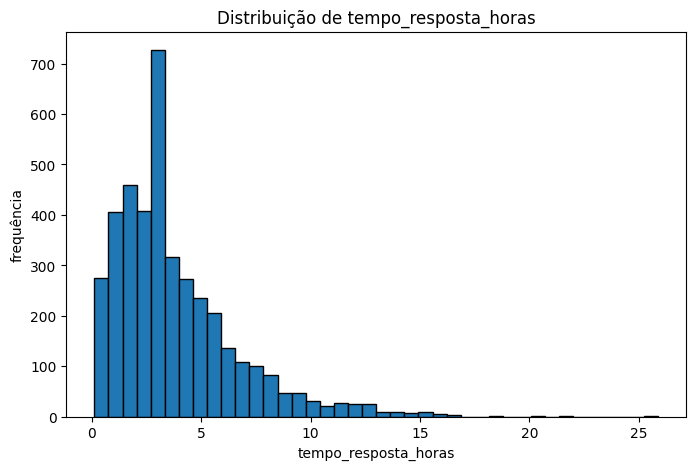

In [58]:
plt.figure(figsize=(8, 5))
plt.hist(df_consolidado["tempo_resposta_horas"], bins=40, edgecolor="black")
plt.xlabel("tempo_resposta_horas")
plt.ylabel("frequência")
plt.title("Distribuição de tempo_resposta_horas")
plt.show()

### 4.2 Construa um boxplot de tempo_resolucao_horas segmentado por prioridade.

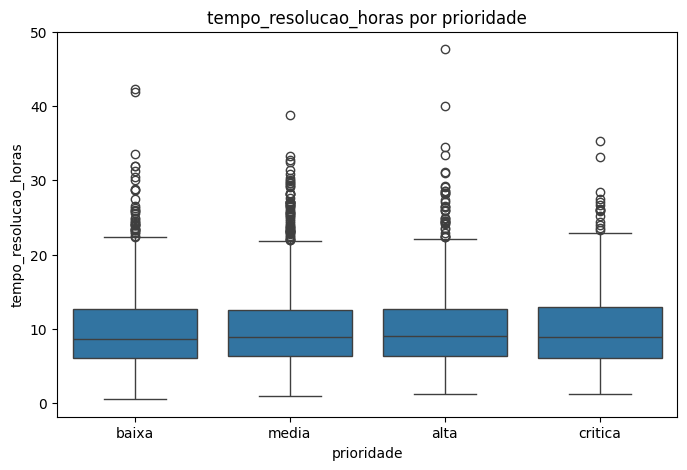

In [59]:
ordem_prioridade = ["baixa", "media", "alta", "critica"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_consolidado, x="prioridade", y="tempo_resolucao_horas", order=ordem_prioridade)
plt.title("tempo_resolucao_horas por prioridade")
plt.show()

### 4.3 Identifique, a partir do boxplot, quais categorias de prioridade concentram mais outliers e registre essa observação em uma célula de markdown.

As quatro caixas (baixa, media, alta, critica) têm mediana e amplitude interquartil visualmente muito parecidas, o que já sugere que a prioridade isolada não é o fator que determina o tempo de resolução. Em relação aos outliers, media é a categoria que concentra visualmente o maior número de pontos acima do limite superior do boxplot, resultado esperado em parte por ser também a categoria com mais tickets, enquanto o outlier isolado mais extremo do gráfico aparece em alta.

##**EXERCÍCIO 5**

### 5.1 Construa um scatter plot de tempo_resposta_horas (eixo X) contra tempo_resolucao_horas (eixo Y).

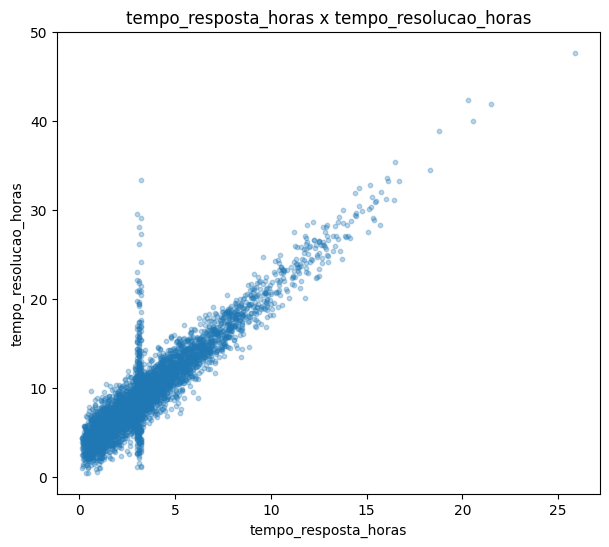

In [60]:
plt.figure(figsize=(7, 6))
plt.scatter(df_consolidado["tempo_resposta_horas"], df_consolidado["tempo_resolucao_horas"], alpha=0.3, s=10)
plt.xlabel("tempo_resposta_horas")
plt.ylabel("tempo_resolucao_horas")
plt.title("tempo_resposta_horas x tempo_resolucao_horas")
plt.show()

### 5.2 Construa um segundo scatter plot de tempo_resposta_horas contra satisfacao_cliente.

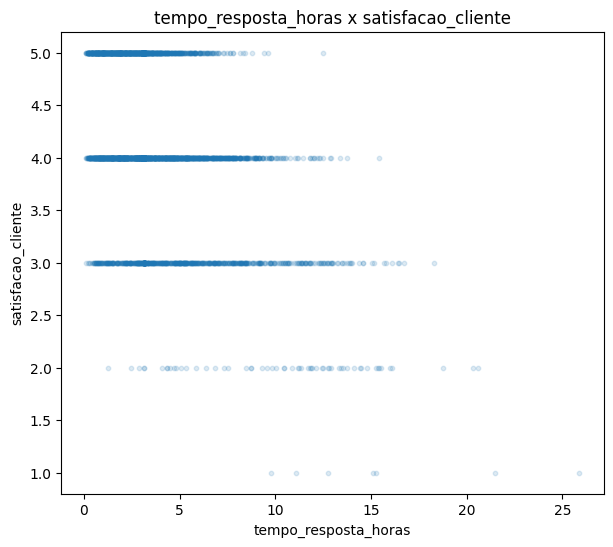

In [61]:
plt.figure(figsize=(7, 6))
plt.scatter(df_consolidado["tempo_resposta_horas"], df_consolidado["satisfacao_cliente"], alpha=0.15, s=10)
plt.xlabel("tempo_resposta_horas")
plt.ylabel("satisfacao_cliente")
plt.title("tempo_resposta_horas x satisfacao_cliente")
plt.show()

### 5.3 Descreva, em uma frase por gráfico, se a relação visual sugere associação linear, não linear ou ausência de relação aparente.

No primeiro gráfico (tempo_resposta_horas x tempo_resolucao_horas), os pontos se concentram bem próximos de uma reta crescente, sugerindo uma associação linear positiva forte. No segundo gráfico (tempo_resposta_horas x satisfacao_cliente), a relação também parece negativa, mas bem menos nítida, como satisfacao_cliente é discreta (1 a 5), os pontos se organizam em faixas horizontais, e o que se observa é que tempos de resposta mais altos concentram cada vez menos pontos nas notas 4 e 5 e mais pontos nas notas 1 e 2.

##**EXERCÍCIO 6**

### 6.1 Selecione as colunas numéricas relevantes do dataset de tickets (tempo_resposta_horas, tempo_resolucao_horas, satisfacao_cliente, entre outras disponíveis).

In [62]:
colunas_numericas = ["tempo_resposta_horas", "tempo_resolucao_horas", "satisfacao_cliente", "valor_plano", "confianca_bot"]
df_consolidado[colunas_numericas].describe()

,tempo_resposta_horas,tempo_resolucao_horas,satisfacao_cliente,valor_plano,confianca_bot
count,4000.000000,4000.000000,3600.000000,4000.000000,1397.000000
mean,3.810830,10.018645,4.106944,213.237500,0.763372
std,2.829979,5.464801,0.758727,144.592169,0.123731
min,0.120000,0.500000,1.000000,99.000000,0.550000
25%,1.860000,6.211823,4.000000,99.000000,0.660000
50%,3.120000,8.866460,4.000000,199.000000,0.770000
75%,4.970000,12.672892,5.000000,199.000000,0.870000
max,25.880000,47.679349,5.000000,599.000000,0.980000


### 6.2 Construa um heatmap de correlação dessas variáveis usando seaborn.

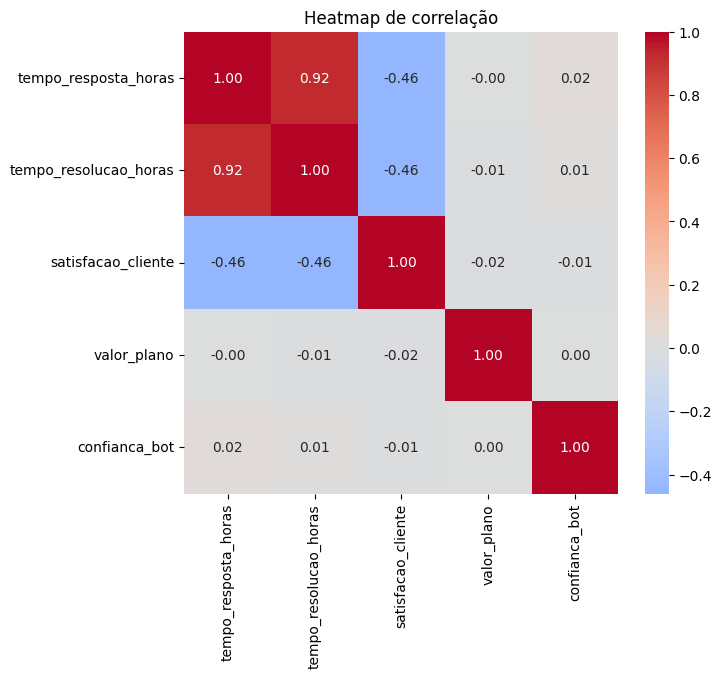

In [63]:
matriz_correlacao = df_consolidado[colunas_numericas].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap de correlação")
plt.show()

### 6.3 Aponte, com base no heatmap, os dois pares de variáveis com maior correlação (positiva ou negativa) e proponha uma hipótese de negócio para cada um.

Os dois pares com maior correlação em módulo são tempo_resposta_horas e tempo_resolucao_horas (r ≈ 0,92, positiva forte) e tempo_resolucao_horas com satisfacao_cliente (r ≈ -0,46, negativa moderada — praticamente empatada com a correlação de tempo_resposta_horas com satisfacao_cliente, de -0,458). valor_plano e confianca_bot não mostram correlação relevante com nenhuma outra variável.

Uma hipótese de negócio para o primeiro par é que boa parte do tempo total de resolução é, na prática, tempo de espera pela primeira resposta, agilizar o primeiro contato tenderia a acelerar a resolução como um todo. Para o segundo par, a hipótese é que atendimentos mais demorados (seja na resposta, seja na resolução) desgastam a percepção do cliente sobre o suporte, reduzindo a nota de satisfação mesmo quando o problema acaba sendo resolvido.

##**EXERCÍCIO 7**

### 7.1 Calcule a matriz de correlação de Pearson das variáveis numéricas selecionadas com pandas.corr().


In [64]:
matriz_correlacao = df_consolidado[colunas_numericas].corr()
print(matriz_correlacao.round(3))

                       tempo_resposta_horas  tempo_resolucao_horas  \
tempo_resposta_horas                  1.000                  0.922   
tempo_resolucao_horas                 0.922                  1.000   
satisfacao_cliente                   -0.458                 -0.460   
valor_plano                          -0.001                 -0.011   
confianca_bot                         0.025                  0.014   

                       satisfacao_cliente  valor_plano  confianca_bot  
tempo_resposta_horas               -0.458       -0.001          0.025  
tempo_resolucao_horas              -0.460       -0.011          0.014  
satisfacao_cliente                  1.000       -0.018         -0.011  
valor_plano                        -0.018        1.000          0.001  
confianca_bot                      -0.011        0.001          1.000  


### 7.2 Calcule a matriz de covariância das mesmas variáveis com pandas.cov().

In [65]:
matriz_covariancia = df_consolidado[colunas_numericas].cov()
print(matriz_covariancia.round(3))

                       tempo_resposta_horas  tempo_resolucao_horas  \
tempo_resposta_horas                  8.009                 14.265   
tempo_resolucao_horas                14.265                 29.864   
satisfacao_cliente                   -0.993                 -1.925   
valor_plano                          -0.462                 -8.946   
confianca_bot                         0.005                  0.006   

                       satisfacao_cliente  valor_plano  confianca_bot  
tempo_resposta_horas               -0.993       -0.462          0.005  
tempo_resolucao_horas              -1.925       -8.946          0.006  
satisfacao_cliente                  0.576       -1.968         -0.001  
valor_plano                        -1.968    20906.895          0.013  
confianca_bot                      -0.001        0.013          0.015  


### 7.3 Explique, em uma frase, por que o coeficiente de correlação é mais interpretável entre variáveis com escalas diferentes do que a covariância bruta.

A correlação de Pearson é a covariância normalizada pelo produto dos desvios padrão das duas variáveis, o que a deixa adimensional e limitada ao intervalo [-1, 1], permitindo comparar diretamente a força de relações entre pares de variáveis com unidades e escalas diferentes; a covariância, em contraste, carrega a escala original das variáveis, o que fica evidente ao comparar a covariância entre tempo_resposta_horas e tempo_resolucao_horas (≈14,26) com a de valor_plano e tempo_resolucao_horas (≈-8,95), os valores não são comparáveis em magnitude porque valor_plano está numa escala de dezenas/centenas de reais, bem diferente da escala em horas das outras variáveis.

##**EXERCÍCIO 8**

### 8.1 Calcule a probabilidade de um cliente dar nota de satisfação igual ou inferior a 2 (insatisfeito), usando frequência relativa.

In [66]:
satisfacao_valida = df_consolidado["satisfacao_cliente"].dropna()
p_insatisfeito = (satisfacao_valida <= 2).mean()

print("P(satisfacao <= 2):", round(p_insatisfeito, 4))

P(satisfacao <= 2): 0.0181


O cálculo considera só os 3600 tickets com satisfacao_cliente preenchida, excluindo os tickets nulos, já que não há como inferir se representam ou não insatisfação). P(insatisfeito) ≈ 0,0181, ou seja, 1,81% dos clientes que avaliaram deram nota 1 ou 2.

### 8.2 Construa um histograma da distribuição de satisfacao_cliente e descreva sua forma (simétrica, assimétrica à esquerda ou à direita).

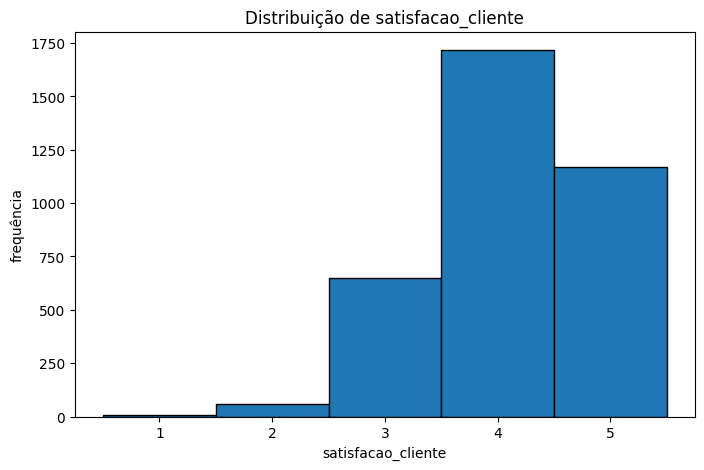

In [67]:
plt.figure(figsize=(8, 5))
plt.hist(satisfacao_valida, bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor="black")
plt.xlabel("satisfacao_cliente")
plt.ylabel("frequência")
plt.title("Distribuição de satisfacao_cliente")
plt.show()

A distribuição de satisfacao_cliente é assimétrica à esquerda: a maior concentração está nas notas 4 (1717 tickets) e 5 (1170), enquanto as notas 1 e 2 juntas somam só 65 dos 3600 tickets avaliados, formando uma cauda longa e fina em direção às notas baixas.

###8.3 Identifique, usando a matriz de correlação do Exercício 7, qual variável tem a correlação mais forte com satisfacao_cliente e escreva um parágrafo curto conectando probabilidade, distribuição e correlação nessa conclusão.

In [68]:
correlacoes_satisfacao = matriz_correlacao["satisfacao_cliente"].drop("satisfacao_cliente").abs().sort_values(ascending=False)
print(correlacoes_satisfacao)

tempo_resolucao_horas    0.460352
tempo_resposta_horas     0.457823
valor_plano              0.017939
confianca_bot            0.010964
Name: satisfacao_cliente, dtype: float64


A variável com correlação mais forte com satisfacao_cliente é tempo_resolucao_horas (r ≈ -0,46), seguida bem de perto por tempo_resposta_horas (r ≈ -0,458). Juntando os três resultados deste exercício, isoladamente, a distribuição de satisfacao_cliente já mostra que a insatisfação é um evento raro (P ≈ 1,81%) concentrado na cauda esquerda de uma distribuição assimétrica, a correlação negativa e moderada com os tempos de resposta e de resolução indica que essa cauda esquerda não é aleatória, mas está associada a atendimentos mais demorados. Ou seja, a baixa probabilidade de insatisfação vista de forma agregada esconde um padrão, entre os tickets mais lentos, a chance de encontrar um cliente insatisfeito é bem maior que a média geral.

##**EXERCÍCIO 9**

###9.1 Construa uma tabela de contingência (crosstab) entre canal e prioridade, com as contagens observadas de cada combinação.

In [69]:
crosstab_canal_prioridade = pd.crosstab(df_consolidado["canal"], df_consolidado["prioridade"])
print(crosstab_canal_prioridade)

prioridade  alta  baixa  critica  media
canal                                  
chat         349    424      143    481
email        485    536      176    641
telefone     182    226       73    284


### 9.2 Calcule a probabilidade conjunta observada P(canal = "chat" e prioridade = "alta") e compare com o produto das probabilidades marginais P(canal = "chat") × P(prioridade = "alta").

In [70]:
p_chat = (df_consolidado["canal"] == "chat").mean()
p_alta = (df_consolidado["prioridade"] == "alta").mean()
p_conjunta_obs = ((df_consolidado["canal"] == "chat") & (df_consolidado["prioridade"] == "alta")).mean()
p_conjunta_indep = p_chat * p_alta

print("P(chat e alta) observada:", round(p_conjunta_obs, 4))
print("P(chat) x P(alta):", round(p_conjunta_indep, 4))

P(chat e alta) observada: 0.0872
P(chat) x P(alta): 0.0887


### 9.3 Escolha mais um par de categorias (canal, prioridade) e repita a mesma comparação.

In [71]:
p_telefone = (df_consolidado["canal"] == "telefone").mean()
p_critica = (df_consolidado["prioridade"] == "critica").mean()
p_conjunta_obs2 = ((df_consolidado["canal"] == "telefone") & (df_consolidado["prioridade"] == "critica")).mean()
p_conjunta_indep2 = p_telefone * p_critica

print("P(telefone e critica) observada:", round(p_conjunta_obs2, 4))
print("P(telefone) x P(critica):", round(p_conjunta_indep2, 4))

P(telefone e critica) observada: 0.0182
P(telefone) x P(critica): 0.0187


### 9.4 Com base nas duas comparações, avalie por escrito se há evidência de que canal e prioridade são independentes ou não, e o que essa conclusão significa para a decisão do líder técnico.

Nos dois pares testados, a probabilidade conjunta observada ficou muito próxima do produto das probabilidades marginais: chat e alta (8,73% observado vs. 8,87% esperado sob independência) e telefone e critica (1,83% vs. 1,87%), com diferença de menos de 0,2 ponto percentual em ambos os casos. Isso é evidência de que canal e prioridade se comportam como variáveis independentes na base consolidada, a prioridade de um ticket não parece depender do canal por onde ele chega. Para a decisão do líder técnico, isso significa que treinar atendentes de um canal específico para tickets urgentes não traria ganho baseado nessa relação, tickets de prioridade alta ou crítica se distribuem proporcionalmente entre email, chat e telefone, então a urgência precisa ser tratada de forma transversal aos canais.

##**EXERCÍCIO 10**

###10.1 Calcule a assimetria (skewness) da distribuição de tempo_resposta_horas.


In [72]:
assimetria_tempo_resposta = stats.skew(df_consolidado["tempo_resposta_horas"])
print("Assimetria (skewness):", round(assimetria_tempo_resposta, 4))

Assimetria (skewness): 1.6851


### 10.2 Construa um histograma da variável sobreposto a uma curva normal com a mesma média e o mesmo desvio padrão dos dados observados.

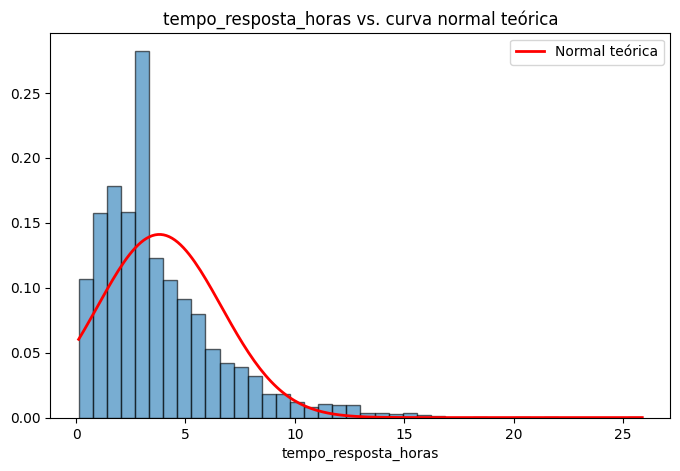

In [73]:
media_tempo_resposta = df_consolidado["tempo_resposta_horas"].mean()
desvio_tempo_resposta = df_consolidado["tempo_resposta_horas"].std()

x = np.linspace(df_consolidado["tempo_resposta_horas"].min(), df_consolidado["tempo_resposta_horas"].max(), 200)
curva_normal = stats.norm.pdf(x, media_tempo_resposta, desvio_tempo_resposta)

plt.figure(figsize=(8, 5))
plt.hist(df_consolidado["tempo_resposta_horas"], bins=40, density=True, edgecolor="black", alpha=0.6)
plt.plot(x, curva_normal, color="red", linewidth=2, label="Normal teórica")
plt.xlabel("tempo_resposta_horas")
plt.legend()
plt.title("tempo_resposta_horas vs. curva normal teórica")
plt.show()

### 10.3 Com base na assimetria calculada e na comparação visual, avalie por escrito se a suposição de normalidade do colega é razoável.

A assimetria calculada (≈1,69) está bem distante de zero, o que já indica uma distribuição fortemente assimétrica à direita, incompatível com a normal (assimetria 0). A sobreposição confirma isso visualmente: a curva normal teórica, construída com a mesma média e desvio padrão dos dados, não acompanha o pico observado entre 2 e 3 horas, subestima a concentração de tickets nessa faixa, superestima a densidade entre 5 e 10 horas e ainda atribui alguma densidade a valores próximos de zero e até negativos, que não fazem sentido para uma variável de tempo. A suposição de normalidade do colega não é razoável, e um SLA calculado sobre média e desvio padrão da normal tenderia a subestimar o tempo real de resposta justamente na cauda direita, que é a parte mais crítica para o SLA.

### 10.4 Proponha, com justificativa, uma família de distribuição mais adequada para tempo_resposta_horas (por exemplo, exponencial ou gama), mesmo sem ajustar formalmente os parâmetros dessa distribuição.

Uma família mais adequada é a distribuição gama, os dados são estritamente não negativos, têm cauda direita longa e, principalmente, o pico da distribuição não está em zero, diferente do que se esperaria de uma exponencial pura, cuja densidade é máxima em zero e decresce monotonicamente. O formato observado, de "sobe até 2-3 horas e depois decai", é a assinatura típica de uma gama com parâmetro de forma maior que 1. A exponencial ficaria em segundo lugar como candidata, mas exigiria assumir uma taxa de decaimento constante já a partir do tempo zero, o que a amostra não sustenta.

##**EXERCÍCIO 11**

###11.1 Calcule a correlação de Pearson entre tempo_resposta_horas e satisfacao_cliente sobre a base completa.

In [74]:
correlacao_geral = df_consolidado["tempo_resposta_horas"].corr(df_consolidado["satisfacao_cliente"])
print("Correlação geral:", round(correlacao_geral, 4))

Correlação geral: -0.4578


### 11.2 Recalcule a mesma correlação separadamente para cada valor de canal.

In [75]:
correlacao_por_canal = df_consolidado.groupby("canal").apply(
    lambda g: g["tempo_resposta_horas"].corr(g["satisfacao_cliente"])
)
print(correlacao_por_canal.round(4))

canal
chat       -0.3683
email      -0.5984
telefone   -0.6270
dtype: float64


/tmp/ipykernel_1506/3414471050.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  correlacao_por_canal = df_consolidado.groupby("canal").apply(


### 11.3 Compare os resultados e escreva uma conclusão sobre se a relação observada na base completa se mantém, enfraquece ou se inverte dentro de algum subgrupo, e o que isso muda (se muda) na recomendação para a diretoria.

A correlação geral entre tempo_resposta_horas e satisfacao_cliente é -0,4578, uma associação negativa moderada. Ao recalcular por canal, a relação se mantém negativa nos três canais, mas com intensidades bem diferentes, fica mais fraca em chat (-0,368) e mais forte em email (-0,598) e telefone (-0,627), inclusive superando a correlação da base completa. Não há inversão de sinal, mas há heterogeneidade relevante, no canal chat, tempo_resposta_horas varia numa faixa mais estreita (desvio padrão ≈1,78h, contra ≈3,1h em email e telefone), com menos variação para explicar, a correlação linear tende a ficar naturalmente mais fraca nesse subgrupo, mesmo que a direção da relação (mais tempo, menos satisfação) se mantenha. Para a diretoria, a recomendação mais segura é priorizar reduções de tempo de resposta em email e telefone, onde o ganho esperado em satisfação por hora reduzida é maior, em vez de aplicar o mesmo peso da correlação agregada igualmente a todos os canais.

##**EXERCÍCIO 12**

### 12.1 Defina, com justificativa técnica por escrito, um critério de "ticket de risco" que combine ao menos: uma condição de probabilidade condicional (por exemplo, P(insatisfeito | alguma condição) elevada), uma característica de distribuição (por exemplo, estar em um percentil superior de tempo_resposta_horas que você escolhe e justifica) e uma relação de correlação já identificada nos Exercícios 7 ou 11.


Critério proposto: um ticket é classificado como de risco quando seu tempo_resposta_horas está acima do percentil 90 observado na base (P90 ≈ 7,56h), essa é a característica de distribuição do critério, escolhida por isolar a cauda direita mais extrema (a mesma cauda que o Exercício 10 mostrou ser bastante assimétrica) sem reduzir demais o volume de tickets analisados.

A justificativa para usar o tempo de resposta como proxy de risco vem da correlação negativa identificada nos Exercícios 7 e 11 entre tempo_resposta_horas e satisfacao_cliente (r entre -0,37 e -0,63, dependendo do canal), tempos de resposta mais altos tendem a andar junto com notas de satisfação mais baixas.

Essa correlação só sustenta o critério, porém, se a condição de probabilidade condicional se confirmar nos dados: P(insatisfeito | ticket de risco) precisa ser sensivelmente maior que P(insatisfeito) na base geral. Isso é verificado no próximo item.

### 12.2 Aplique esse critério à base de tickets e reporte quantos tickets são classificados como "de risco".

In [76]:
p90_tempo_resposta = df_consolidado["tempo_resposta_horas"].quantile(0.90)

satisfacao_valida_df = df_consolidado.dropna(subset=["satisfacao_cliente"])
p_insatisfeito_geral = (satisfacao_valida_df["satisfacao_cliente"] <= 2).mean()

tickets_lentos_validos = satisfacao_valida_df[satisfacao_valida_df["tempo_resposta_horas"] > p90_tempo_resposta]
p_insatisfeito_dado_lento = (tickets_lentos_validos["satisfacao_cliente"] <= 2).mean()

df_consolidado["ticket_de_risco"] = df_consolidado["tempo_resposta_horas"] > p90_tempo_resposta
total_risco = df_consolidado["ticket_de_risco"].sum()

print("P90 tempo_resposta_horas:", round(p90_tempo_resposta, 2))
print("P(insatisfeito) geral:", round(p_insatisfeito_geral, 4))
print("P(insatisfeito | ticket de risco):", round(p_insatisfeito_dado_lento, 4))
print("Total de tickets 'de risco':", total_risco, f"({total_risco / len(df_consolidado) * 100:.1f}%)")

P90 tempo_resposta_horas: 7.56
P(insatisfeito) geral: 0.0181
P(insatisfeito | ticket de risco): 0.1298
Total de tickets 'de risco': 400 (10.0%)


O critério classificou 400 tickets (10% da base) como "de risco". Entre eles, P(insatisfeito) sobe para 12,98%, cerca de 7,2 vezes a probabilidade de insatisfação da base geral (1,81%), evidência de que a condição de probabilidade condicional elevada exigida pelo critério de fato se confirma nos dados.

### 12.3 Avalie criticamente o critério proposto, apontando pelo menos uma limitação real dele (por exemplo, sensibilidade ao percentil escolhido, ou possíveis falsos positivos), e sugira por escrito um ajuste possível.

In [77]:
for percentil in [0.80, 0.85, 0.90, 0.95]:
    limite = df_consolidado["tempo_resposta_horas"].quantile(percentil)
    qtd_tickets = (df_consolidado["tempo_resposta_horas"] > limite).sum()
    print(f"P{int(percentil * 100)} = {limite:.2f}h -> {qtd_tickets} tickets classificados")

print("\nCanal dos tickets de risco (P90):")
print(df_consolidado.loc[df_consolidado["ticket_de_risco"], "canal"].value_counts())
print("\nCanal na base completa:")
print(df_consolidado["canal"].value_counts())

P80 = 5.56h -> 799 tickets classificados
P85 = 6.37h -> 600 tickets classificados
P90 = 7.56h -> 400 tickets classificados
P95 = 9.41h -> 199 tickets classificados

Canal dos tickets de risco (P90):
canal
email       262
telefone    112
chat         26
Name: count, dtype: int64

Canal na base completa:
canal
email       1838
chat        1397
telefone     765
Name: count, dtype: int64


O critério tem pelo menos duas limitações. A primeira é a sensibilidade ao percentil escolhido: variando o corte de P80 para P95, o número de tickets classificados como "de risco" varia de 799 (20% da base) a 199 (5%), a fronteira de "risco" é uma escolha de negócio, não algo determinado pelos dados, e um percentil mais frouxo dilui o time de retenção em tickets menos urgentes, enquanto um percentil mais rígido pode deixar de fora clientes também insatisfeitos.

A segunda limitação é o desbalanceamento entre canais, apenas 26 dos 400 tickets de risco (6,5%) vêm do canal chat, mesmo esse canal representando quase 35% da base, resultado esperado, já que o Exercício 11 mostrou que a correlação entre tempo_resposta_horas e satisfacao_cliente é mais fraca justamente em chat. Isso sugere que o critério, do jeito que está definido, tende a gerar falsos negativos especificamente entre clientes atendidos por chat, onde o tempo de resposta é um sinal mais fraco de insatisfação. Um ajuste possível é calcular o percentil de corte separadamente por canal, em vez de usar um único limite global, para que o critério capture o comportamento relativo de cada canal em vez de comparar tempos de resposta em escalas naturalmente diferentes entre eles.